# PHẦN I - HỆ THỐNG DỰ ĐOÁN BỆNH TIỂU ĐƯỜNG

**Môn học:** Phát triển các hệ thống thông minh — **Bài tập 1**
**Họ và tên:** Phan Văn Khôi — **Mã sinh viên:** B23DCCN447 — **Lớp:** D23CTPM01

Notebook này tái hiện toàn bộ quy trình trong báo cáo: từ đọc dữ liệu Pima Indians Diabetes,
tiền xử lý, EDA, huấn luyện và so sánh 4 mô hình phân loại, cho tới việc lưu weight
(`models/*.sav`) phục vụ REST API và giao diện web.

## 1. Định nghĩa hệ thống và bài toán

### 1.1. Bối cảnh và mục tiêu

Đái tháo đường là một vấn đề sức khoẻ cần được nhận diện sớm để hỗ trợ tư vấn, theo dõi và
quyết định khám chuyên khoa. Hệ thống được xây dựng nhằm ước lượng nguy cơ có kết quả xét
nghiệm dương tính với đái tháo đường từ các chỉ số lâm sàng cơ bản.

Mục tiêu chính: xây dựng và so sánh nhiều mô hình phân loại, chọn mô hình có hiệu quả tốt
nhất, sau đó đóng gói thành REST API và giao diện web để người dùng có thể nhập thông tin và
nhận kết quả dự đoán.

### 1.2. Phát biểu hệ thống thông minh

Hệ thống nhận đầu vào là các chỉ số sức khoẻ của bệnh nhân, sử dụng mô hình học máy đã được
huấn luyện trên bộ dữ liệu Pima Indians Diabetes để đưa ra dự đoán nguy cơ tiểu đường
(`Outcome` = 0 hoặc 1) kèm theo xác suất/độ tin cậy.

- **Tầng dữ liệu:** bộ dữ liệu Pima Indians Diabetes (768 mẫu, 8 đặc trưng)
- **Tầng mô hình:** Logistic Regression, KNN, SVM Linear, SVM RBF
- **Tầng ứng dụng:** REST API (Flask) và giao diện web

### 1.3. Phát biểu bài toán học có giám sát

Đây là bài toán **phân loại nhị phân có giám sát**. Với mỗi bệnh nhân có vector đặc trưng
x = (Glucose, BMI, Age), mô hình cần dự đoán nhãn y ∈ {0, 1}.

- **Đầu vào:** Glucose, BMI, Age
- **Đầu ra:** Outcome = 0 (không tiểu đường) hoặc 1 (có tiểu đường)

## 2. Sơ đồ hệ thống thông minh

### 2.1. Luồng hoạt động

**GIAI ĐOẠN HUẤN LUYỆN (offline):**

```
diabetes.csv → Tiền xử lý (thay 0 bằng NaN, impute bằng mean) → Chọn đặc trưng
→ Chia Train/Test (stratify, 80/20) → Baseline (DummyClassifier) → Huấn luyện 4 mô hình
→ Đánh giá (Accuracy, Precision, Recall, F1, Confusion Matrix) → Chọn model tốt nhất → Lưu .sav
```

**GIAI ĐOẠN TRIỂN KHAI (online):**

```
Người dùng nhập chỉ số → Flask REST API → Pipeline (StandardScaler + Predict)
→ Kết quả: prediction (0/1) + confidence (%)
```

### 2.2. Vì sao đây là một hệ thống thông minh?

Thành phần "thông minh" không chỉ là lệnh gọi `predict`. Hệ thống nhận thông tin, duy trì một
biểu diễn tính toán, học quy luật từ các ví dụ có nhãn và khái quát hoá để dự đoán trường hợp
mới. Tầng ứng dụng `REST_API.py` đảm bảo dữ liệu mới đi qua cùng pipeline tiền xử lý như lúc
huấn luyện.

### 2.3. Ranh giới hệ thống

Hệ thống chỉ cung cấp một dự đoán thống kê trong phạm vi dữ liệu Pima Indians Diabetes, không
đưa ra phác đồ điều trị hoặc khẳng định chẩn đoán y khoa.

## 3. Nguồn dữ liệu

| Nội dung | Thông tin |
| --- | --- |
| Tên bộ dữ liệu | Pima Indians Diabetes Dataset |
| Nguồn | Kaggle - Pima Indians Diabetes Dataset |
| Nguồn gốc | NIDDK (National Institute of Diabetes and Digestive and Kidney Diseases) |
| Tệp | `data/diabetes.csv` |
| Miền bài toán | Phân loại nguy cơ đái tháo đường |

Bộ dữ liệu gồm 768 quan sát, 8 thuộc tính đầu vào số và 1 nhãn đầu ra; bệnh nhân thuộc nhóm
phụ nữ Pima Indians từ 21 tuổi trở lên.

## 4. Mô tả dữ liệu

### 4.1. Đơn vị quan sát, quy mô và loại bài toán

768 quan sát, 8 đặc trưng đầu vào, 1 biến mục tiêu (`Outcome`). Phân loại nhị phân có giám sát.
Phân bố lớp: 500 mẫu lớp 0, 268 mẫu lớp 1.

### 4.2. Ý nghĩa các đặc trưng

| Đặc trưng | Kiểu | Ý nghĩa |
| --- | --- | --- |
| Pregnancies | Số nguyên | Số lần mang thai |
| Glucose | Số | Nồng độ glucose sau 2h (mg/dL) |
| BloodPressure | Số | Huyết áp tâm trương (mm Hg) |
| SkinThickness | Số | Độ dày nếp da (mm) |
| Insulin | Số | Insulin huyết thanh sau 2h (mu U/ml) |
| BMI | Số thực | Chỉ số khối cơ thể (kg/m²) |
| DiabetesPedigreeFunction | Số thực | Tiền sử gia đình |
| Age | Số nguyên | Tuổi (năm) |
| Outcome | Nhị phân | Nhãn mục tiêu (0/1) |

### 4.3. Lưu ý chất lượng dữ liệu

Giá trị 0 ở `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI` là giá trị thiếu được
mã hoá. Xử lý: thay 0 bằng `NaN` rồi impute bằng mean.

### 4.4. Cơ sở lý thuyết các mô hình phân loại

1. **Logistic Regression** — z = β₀ + β₁x₁ + ... → sigmoid → P(y=1|x). Ưu: nhanh, dễ giải thích.
2. **KNN** — chọn K mẫu gần nhất, bỏ phiếu theo nhãn. Cần chuẩn hoá. K chọn bằng CV.
3. **SVM tuyến tính** — tìm siêu phẳng margin lớn nhất. Tham số C điều khiển trade-off.
4. **SVM RBF** — kernel K(x, xᵢ) = exp[-γ‖x - xᵢ‖²]. Học ranh giới phi tuyến.

### 4.5. Cơ sở lý thuyết chỉ số đánh giá

Accuracy = (TP+TN)/(TP+TN+FP+FN). Precision = TP/(TP+FP). Recall = TP/(TP+FN).
F1 = 2·P·R/(P+R). Với dữ liệu lệch lớp, F1 và Recall quan trọng hơn Accuracy.

## 5. Biểu diễn dữ liệu

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

candidate_paths = [
    Path("../data/diabetes.csv"),
    Path("data/diabetes.csv"),
    Path("src/Assignment 01/diabetes/data/diabetes.csv"),
]

DATA_PATH = next((p for p in candidate_paths if p.exists()), None)
if DATA_PATH is None:
    searched = "; ".join(str(p) for p in candidate_paths)
    raise FileNotFoundError(f"Không tìm thấy tệp dữ liệu. Đã thử: {searched}")
DATA_PATH = DATA_PATH.resolve()

df = pd.read_csv(DATA_PATH)
df_raw = df.copy()

print(f"Đã đọc dữ liệu từ: {DATA_PATH}")
df.info()

Đã đọc dữ liệu từ: /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 01/diabetes/data/diabetes.csv
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    float64
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    float64
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(4), int64(5)
memory usage: 54.1 KB


In [2]:
# Thư mục lưu hình và weight (dùng lại ở mục 18)
PROJECT_DIR = DATA_PATH.parent.parent
FIGURE_DIR = PROJECT_DIR / "report" / "figures"
MODEL_DIR = PROJECT_DIR / "models"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)


def save_current_figure(filename):
    output_path = FIGURE_DIR / filename
    plt.savefig(output_path, dpi=150, bbox_inches="tight")
    return output_path


print(f"Hình: {FIGURE_DIR}")
print(f"Weight: {MODEL_DIR}")

Hình: /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 01/diabetes/report/figures
Weight: /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 01/diabetes/models


## 6. Phân tích đặc trưng và biến mục tiêu

Kiểm tra null và giá trị 0 bất thường.

In [3]:
print("Nulls")
print("=====")
print(df.isnull().sum())

# Kiểm tra giá trị 0 bất thường
print("\nGiá trị 0 theo từng cột:")
print("========================")
print(df.eq(0).sum())

Nulls
=====
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Giá trị 0 theo từng cột:
Pregnancies                 111
Glucose                       0
BloodPressure                 0
SkinThickness                 0
Insulin                       0
BMI                           0
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64


In [4]:
display(df_raw[["Glucose", "BMI", "Age", "Outcome"]].describe().T)

,count,mean,std,min,25%,50%,75%,max
Glucose,768.0,121.677083,30.464161,44.0,99.75,117.00,140.25,199.0
BMI,768.0,32.434635,6.880498,18.2,27.50,32.05,36.60,67.1
Age,768.0,33.240885,11.760232,21.0,24.00,29.00,41.00,81.0
Outcome,768.0,0.348958,0.476951,0.0,0.00,0.00,1.00,1.0


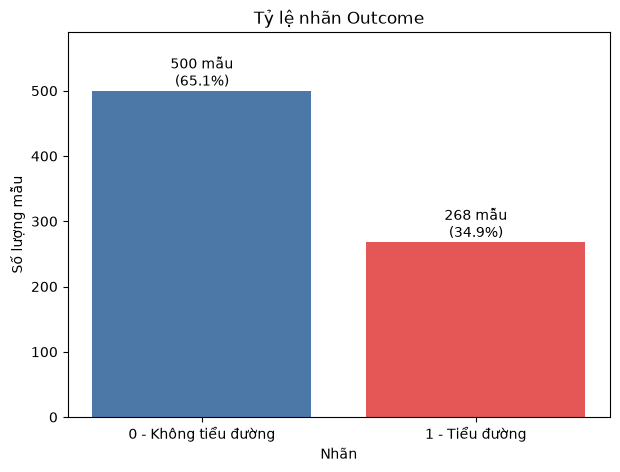

In [5]:
# Biểu đồ tỷ lệ nhãn Outcome
import matplotlib.pyplot as plt

label_counts = df["Outcome"].value_counts().sort_index()
label_percentages = label_counts / label_counts.sum() * 100

plt.figure(figsize=(7, 5))
bars = plt.bar(
    ["0 - Không tiểu đường", "1 - Tiểu đường"],
    label_counts.values,
    color=["#4C78A8", "#E45756"]
)
plt.title("Tỷ lệ nhãn Outcome")
plt.xlabel("Nhãn")
plt.ylabel("Số lượng mẫu")
for bar, count, percentage in zip(bars, label_counts.values, label_percentages.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 8,
        f"{count} mẫu\n({percentage:.1f}%)",
        ha="center"
    )
plt.ylim(0, label_counts.max() * 1.18)
save_current_figure("diabetes_outcome_balance.png")
plt.show()

=> Bộ dữ liệu thiên lệch nhẹ: 65.1% lớp 0, 34.9% lớp 1.

In [6]:
# Thay giá trị 0 bất thường bằng NaN rồi impute bằng mean
columns_with_invalid_zeros = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
]

df[columns_with_invalid_zeros] = df[columns_with_invalid_zeros].replace(0, np.nan)
df.fillna(df.mean(), inplace=True)

print("Sau khi xử lý giá trị 0:")
print(df.eq(0).sum())

Sau khi xử lý giá trị 0:
Pregnancies                 111
Glucose                       0
BloodPressure                 0
SkinThickness                 0
Insulin                       0
BMI                           0
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64


### 6.1. Gỡ phần impute theo nhãn còn sót trong tệp CSV

Tệp `data/diabetes.csv` đã được impute sẵn một phần **theo từng nhãn Outcome** chứ không phải
bằng mean toàn cục như báo cáo mô tả. Hệ quả: `Insulin = 102.5` xuất hiện 236 lần và toàn bộ
đều là Outcome = 0, còn `Insulin = 169.5` xuất hiện 138 lần và toàn bộ đều là Outcome = 1 —
tức là giá trị đã mang sẵn thông tin nhãn (*label leakage*). Nếu giữ nguyên, các mô hình dùng
`Insulin`/`SkinThickness` sẽ cho điểm cao giả tạo.

Cell dưới đây phát hiện các giá trị sentinel đó (lặp lại ≥ 50 lần và ≥ 85% rơi vào một nhãn),
trả chúng về `NaN` rồi impute lại bằng **mean toàn cục** — đúng như quy trình mục 4.3 của báo cáo.

In [7]:
# Phát hiện giá trị sentinel do impute theo nhãn
MIN_COUNT = 50
MIN_PURITY = 0.85

leak_report = []
for column in columns_with_invalid_zeros:
    grouped = df.groupby(column)["Outcome"].agg(["count", "mean"])
    suspicious = grouped[
        (grouped["count"] >= MIN_COUNT)
        & ((grouped["mean"] >= MIN_PURITY) | (grouped["mean"] <= 1 - MIN_PURITY))
    ]
    for value, row in suspicious.iterrows():
        leak_report.append({
            "Cột": column,
            "Giá trị": value,
            "Số dòng": int(row["count"]),
            "Tỷ lệ Outcome=1": round(float(row["mean"]), 3),
        })
        df.loc[df[column] == value, column] = np.nan

if leak_report:
    print("Các giá trị bị nghi là impute theo nhãn (đã trả về NaN):")
    display(pd.DataFrame(leak_report))
    df.fillna(df.mean(), inplace=True)
    print("\nĐã impute lại bằng mean toàn cục.")
else:
    print("Không phát hiện giá trị impute theo nhãn.")

print("\nKiểm tra lại độ 'thuần nhãn' của Insulin sau khi xử lý:")
print(df.groupby("Insulin")["Outcome"].agg(["count", "mean"]).sort_values("count", ascending=False).head(3))

Các giá trị bị nghi là impute theo nhãn (đã trả về NaN):


,Cột,Giá trị,Số dòng,Tỷ lệ Outcome=1
0,SkinThickness,27.0,162,0.043
1,SkinThickness,32.0,119,0.857
2,Insulin,102.5,236,0.000
3,Insulin,169.5,138,1.000



Đã impute lại bằng mean toàn cục.

Kiểm tra lại độ 'thuần nhãn' của Insulin sau khi xử lý:
            count      mean
Insulin                    
155.548223    374  0.368984
105.000000     11  0.090909
130.000000      9  0.666667


## 7. Phân tích khám phá dữ liệu (EDA)

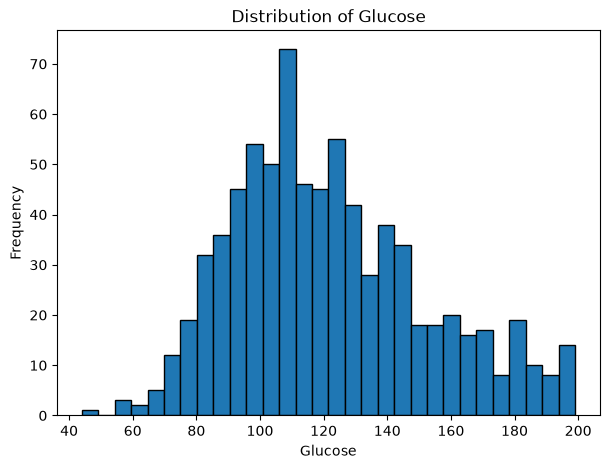

In [8]:
# Biểu đồ phân phối Glucose
plt.figure(figsize=(7, 5))
plt.hist(df['Glucose'], bins=30, edgecolor='black')
plt.title('Distribution of Glucose')
plt.xlabel('Glucose')
plt.ylabel('Frequency')
save_current_figure("diabetes_glucose_distribution.png")
plt.show()

=> Glucose tập trung khoảng 80-140, đỉnh gần 100-110. Lệch phải.

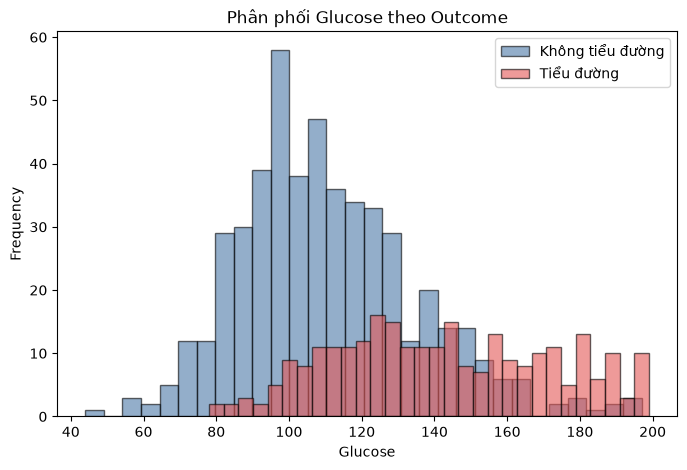

In [9]:
# Phân phối Glucose theo Outcome
plt.figure(figsize=(8, 5))
for outcome, color, label in [(0, "#4C78A8", "Không tiểu đường"), (1, "#E45756", "Tiểu đường")]:
    plt.hist(
        df.loc[df["Outcome"] == outcome, "Glucose"],
        bins=30, alpha=0.6, color=color, edgecolor="black", label=label
    )
plt.title("Phân phối Glucose theo Outcome")
plt.xlabel("Glucose")
plt.ylabel("Frequency")
plt.legend()
save_current_figure("diabetes_glucose_by_outcome.png")
plt.show()

=> Nhóm Outcome=1 tập trung ở Glucose cao hơn (125-200), Outcome=0 quanh 85-125.

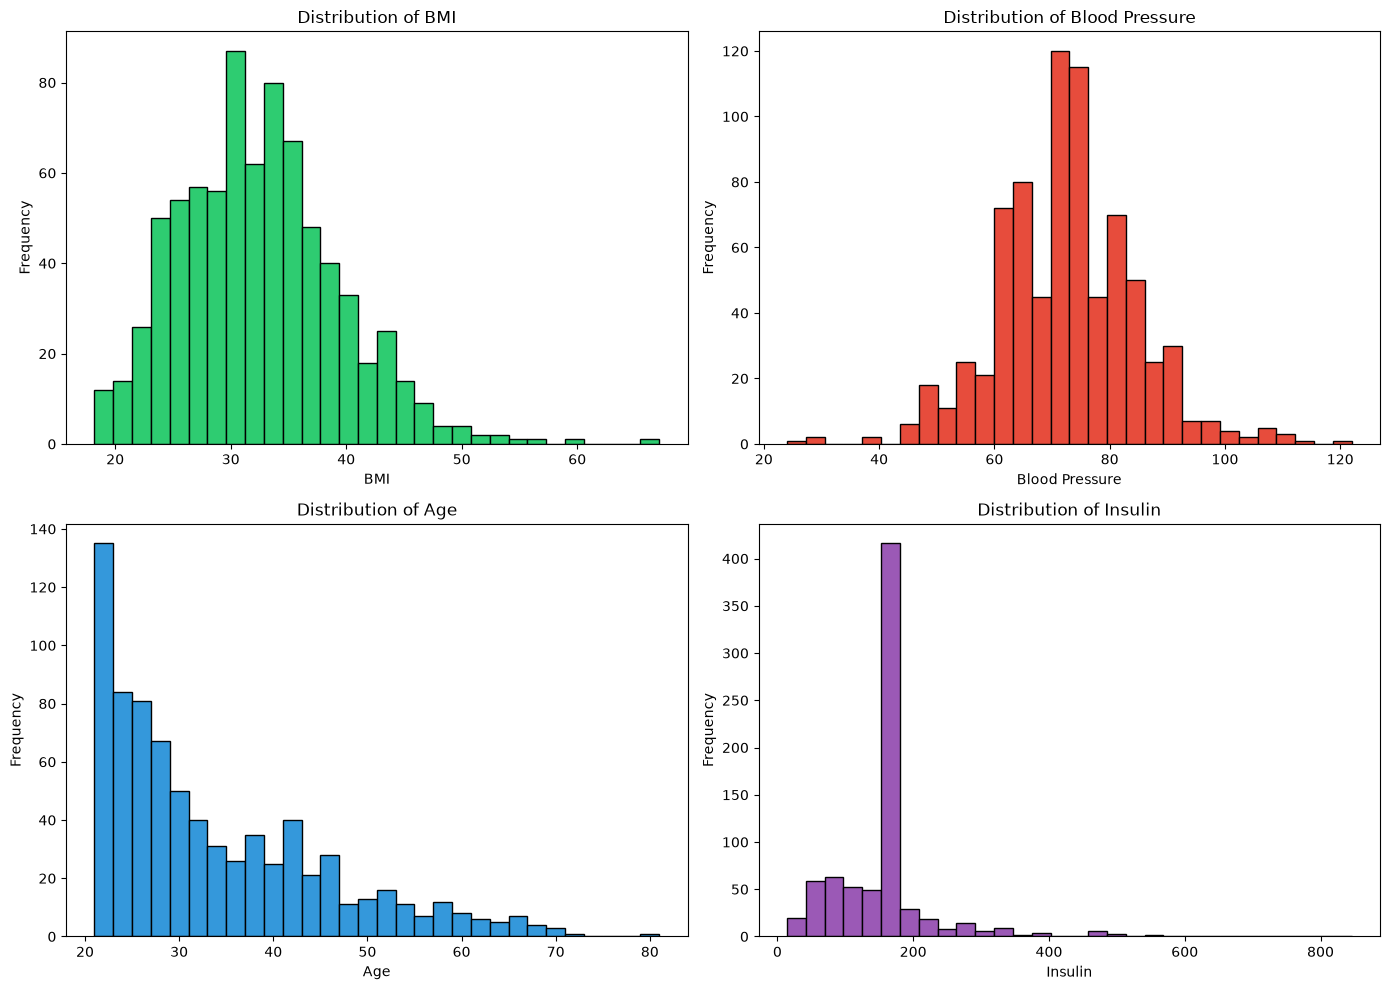

In [10]:
# Biểu đồ phân phối BMI, BloodPressure, Age, Insulin
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].hist(df['BMI'], bins=30, edgecolor='black', color='#2ecc71')
axes[0, 0].set_title('Distribution of BMI')
axes[0, 0].set_xlabel('BMI')

axes[0, 1].hist(df['BloodPressure'], bins=30, edgecolor='black', color='#e74c3c')
axes[0, 1].set_title('Distribution of Blood Pressure')
axes[0, 1].set_xlabel('Blood Pressure')

axes[1, 0].hist(df['Age'], bins=30, edgecolor='black', color='#3498db')
axes[1, 0].set_title('Distribution of Age')
axes[1, 0].set_xlabel('Age')

axes[1, 1].hist(df['Insulin'], bins=30, edgecolor='black', color='#9b59b6')
axes[1, 1].set_title('Distribution of Insulin')
axes[1, 1].set_xlabel('Insulin')

for ax in axes.flat:
    ax.set_ylabel('Frequency')

plt.tight_layout()
save_current_figure("diabetes_feature_distributions.png")
plt.show()

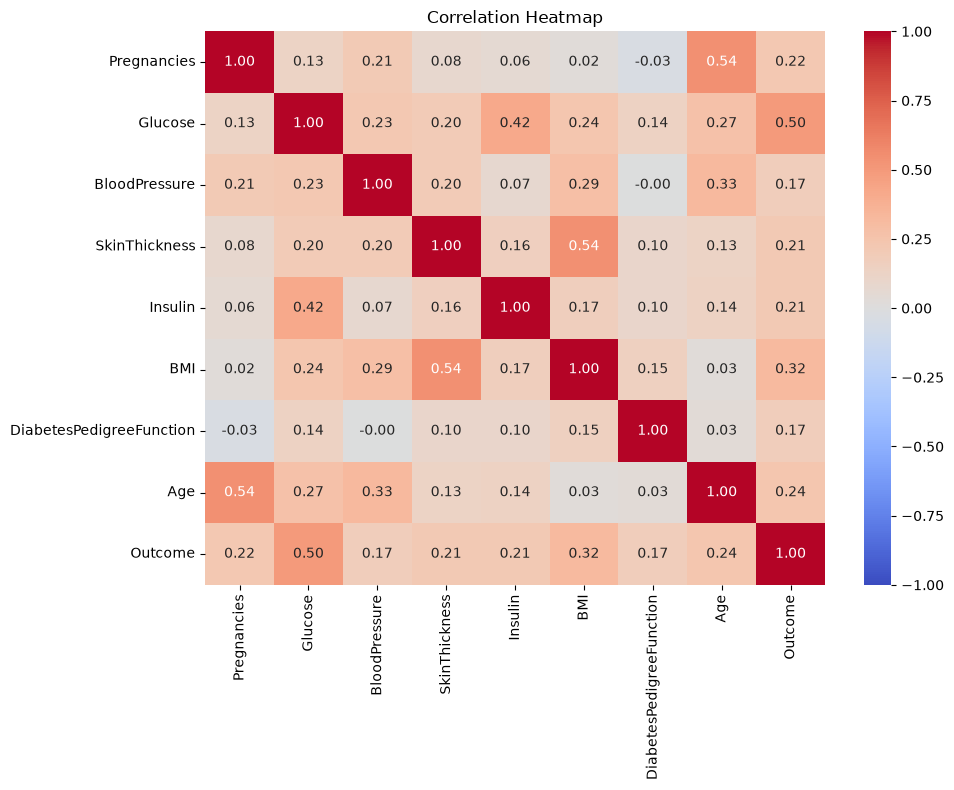

In [11]:
# Ma trận tương quan
import seaborn as sns

corr = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)
plt.title("Correlation Heatmap")
plt.tight_layout()
save_current_figure("diabetes_correlation_heatmap.png")
plt.show()

=> Glucose có tương quan dương mạnh nhất với Outcome (r ≈ 0.49), tiếp theo BMI (r ≈ 0.31), Age (r ≈ 0.24).

In [12]:
# Chọn top features có tương quan cao nhất với Outcome
print(df.corr(numeric_only=True).nlargest(7, 'Outcome')['Outcome'])

Outcome          1.000000
Glucose          0.495990
BMI              0.315577
Age              0.238356
Pregnancies      0.221898
Insulin          0.214411
SkinThickness    0.212172
Name: Outcome, dtype: float64


=> Từ ma trận tương quan, Glucose có tương quan dương mạnh nhất với Outcome (r ≈ 0.49), tiếp
theo là BMI (r ≈ 0.31) và Age (r ≈ 0.24). Chọn 3 feature cơ sở: **Glucose, BMI, Age**.

## 8. Chia tập huấn luyện/kiểm tra (3 feature)

Chọn 3 feature: Glucose, BMI, Age. Chia 80/20 với stratify theo Outcome, `random_state=42`.

In [13]:
from sklearn.model_selection import train_test_split

FEATURE_COLUMNS = ["Glucose", "BMI", "Age"]
TARGET_COLUMN = "Outcome"

X_raw, y = df[FEATURE_COLUMNS], df[TARGET_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Tập huấn luyện: {X_train.shape}; Tập kiểm tra: {X_test.shape}")
print("Các cột của X_train:", X_train.columns.tolist())
print("Số feature:", X_train.shape[1])

Tập huấn luyện: (614, 3); Tập kiểm tra: (154, 3)
Các cột của X_train: ['Glucose', 'BMI', 'Age']
Số feature: 3


## 9. Mô hình cơ sở (Baseline)

`DummyClassifier(strategy="most_frequent")` luôn dự đoán lớp 0.

In [14]:
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

baseline_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DummyClassifier(strategy="most_frequent", random_state=42))
])
baseline_model.fit(X_train, y_train)
baseline_pred = baseline_model.predict(X_test)

display(pd.DataFrame([{
    "Model": "Mô hình cơ sở (lớp xuất hiện nhiều nhất)",
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Precision": precision_score(y_test, baseline_pred, zero_division=0),
    "Recall": recall_score(y_test, baseline_pred, zero_division=0),
    "F1-score": f1_score(y_test, baseline_pred, zero_division=0),
}]))

,Model,Accuracy,Precision,Recall,F1-score
0,Mô hình cơ sở (lớp xuất hiện nhiều nhất),0.649351,0.0,0.0,0.0


Baseline đạt Accuracy cao do mất cân bằng nhưng không phát hiện bất kỳ ca dương tính nào.
Mọi model phải vượt mốc này.

## 10. Mô hình 1 — Hồi quy Logistic

,Train,Test
Accuracy,0.783388,0.707792
Precision,0.742515,0.595745
Recall,0.579439,0.518519
F1-score,0.650919,0.554455


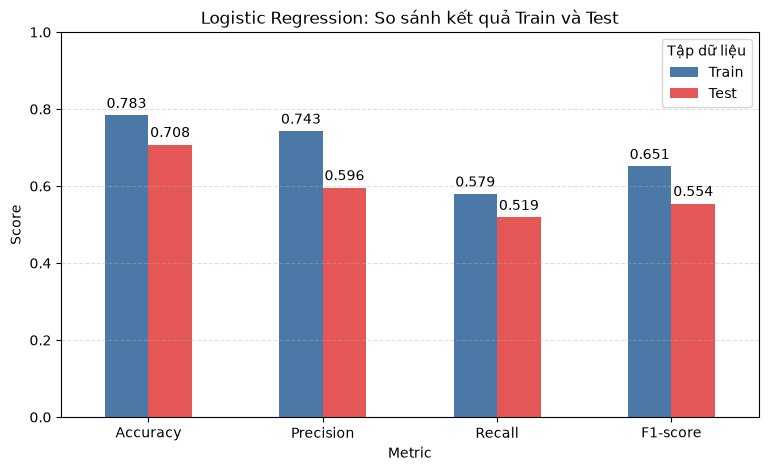

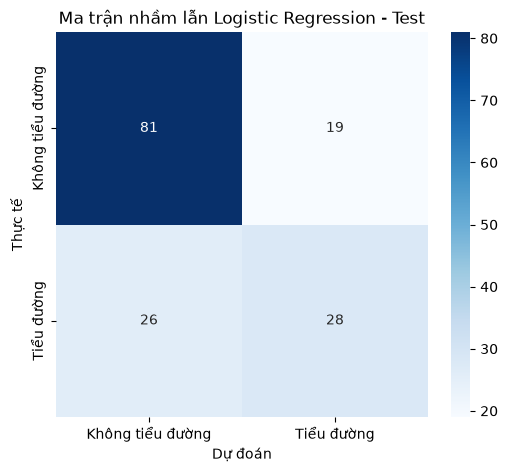

In [15]:
from sklearn.linear_model import LogisticRegression

results = []

log_regress = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])
log_regress.fit(X_train, y_train)

y_train_pred = log_regress.predict(X_train)
y_test_pred = log_regress.predict(X_test)

metrics_df = pd.DataFrame({
    "Train": [
        accuracy_score(y_train, y_train_pred),
        precision_score(y_train, y_train_pred, zero_division=0),
        recall_score(y_train, y_train_pred, zero_division=0),
        f1_score(y_train, y_train_pred, zero_division=0)
    ],
    "Test": [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred, zero_division=0),
        recall_score(y_test, y_test_pred, zero_division=0),
        f1_score(y_test, y_test_pred, zero_division=0)
    ]
}, index=["Accuracy", "Precision", "Recall", "F1-score"])
display(metrics_df)

# Biểu đồ Train - Test
ax = metrics_df.plot(kind="bar", figsize=(9, 5), color=["#4C78A8", "#E45756"])
plt.title("Logistic Regression: So sánh kết quả Train và Test")
plt.xlabel("Metric"); plt.ylabel("Score"); plt.ylim(0, 1)
plt.xticks(rotation=0); plt.legend(title="Tập dữ liệu")
plt.grid(axis="y", linestyle="--", alpha=0.4)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)
save_current_figure("diabetes_logistic_train_test.png")
plt.show()

# Confusion matrix
cm_test = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Không tiểu đường", "Tiểu đường"],
    yticklabels=["Không tiểu đường", "Tiểu đường"])
plt.title("Ma trận nhầm lẫn Logistic Regression - Test")
plt.xlabel("Dự đoán"); plt.ylabel("Thực tế")
save_current_figure("diabetes_logistic_confusion_matrix.png")
plt.show()

accuracy = metrics_df.loc["Accuracy", "Test"]
precision = metrics_df.loc["Precision", "Test"]
recall = metrics_df.loc["Recall", "Test"]
f1 = metrics_df.loc["F1-score", "Test"]
results.append({'Model': 'Logistic Regression', 'Accuracy': accuracy,
                'Precision': precision, 'Recall': recall, 'F1-score': f1})

Logistic Regression đạt Accuracy ~70.8% trên test, vượt baseline. Tuy nhiên Recall ~51.9% và
F1 ~55.4% cho thấy model còn bỏ sót nhiều ca dương tính.

## 11. Mô hình 2 — KNN

Khảo sát k tối ưu bằng 10-fold CV (`scoring="f1"`).

K tối ưu: 43
F1-score CV tốt nhất: 0.6759


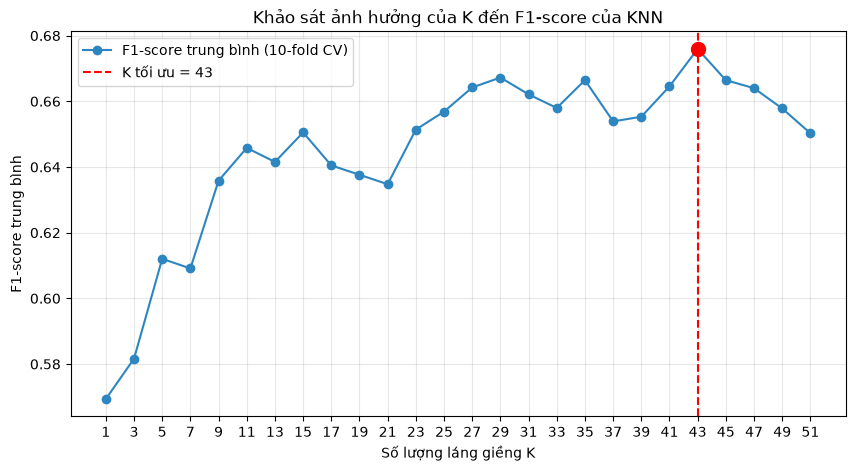

In [16]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Tìm K tối ưu bằng 10-fold CV
folds = 10
cv = StratifiedKFold(n_splits=folds, shuffle=True, random_state=42)
ks = list(range(1, 52, 2))
cv_scores = []

for k in ks:
    knn_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k))
    ])
    score = cross_val_score(knn_pipeline, X_train, y_train, cv=cv, scoring="f1").mean()
    cv_scores.append(score)

optimal_k = ks[cv_scores.index(max(cv_scores))]
best_cv_f1 = max(cv_scores)
print(f"K tối ưu: {optimal_k}")
print(f"F1-score CV tốt nhất: {best_cv_f1:.4f}")

# Biểu đồ khảo sát K
plt.figure(figsize=(10, 5))
plt.plot(ks, cv_scores, marker="o", color="#2E86C1", label="F1-score trung bình (10-fold CV)")
plt.axvline(optimal_k, color="red", linestyle="--", label=f"K tối ưu = {optimal_k}")
plt.scatter(optimal_k, best_cv_f1, color="red", s=100, zorder=3)
plt.title("Khảo sát ảnh hưởng của K đến F1-score của KNN")
plt.xlabel("Số lượng láng giềng K"); plt.ylabel("F1-score trung bình")
plt.xticks(ks); plt.grid(alpha=0.3); plt.legend()
save_current_figure("diabetes_knn_k_search.png")
plt.show()

,Train,Test
Accuracy,0.799674,0.740260
Precision,0.757062,0.652174
Recall,0.626168,0.555556
F1-score,0.685422,0.600000


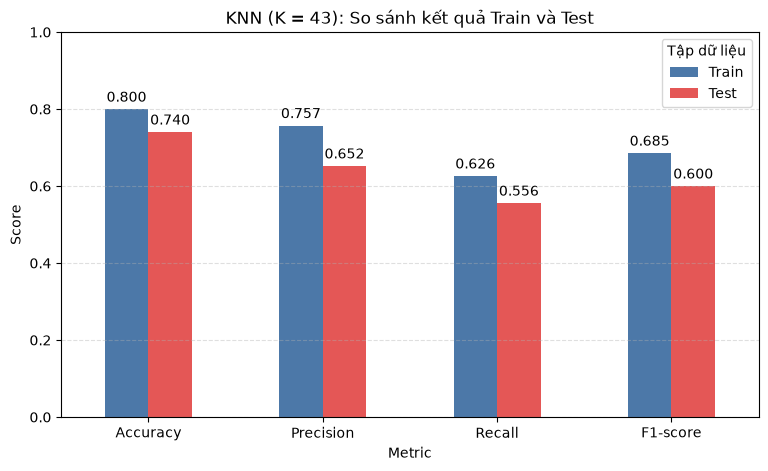

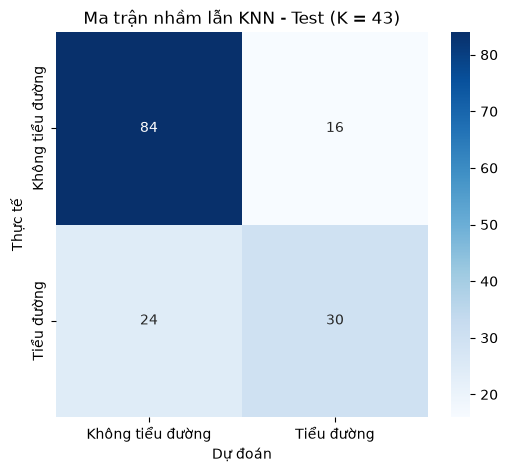

In [17]:
# Huấn luyện KNN với K tối ưu
knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=optimal_k))
])
knn.fit(X_train, y_train)
y_train_pred = knn.predict(X_train)
y_test_pred = knn.predict(X_test)

metrics_df = pd.DataFrame({
    "Train": [
        accuracy_score(y_train, y_train_pred),
        precision_score(y_train, y_train_pred, zero_division=0),
        recall_score(y_train, y_train_pred, zero_division=0),
        f1_score(y_train, y_train_pred, zero_division=0)
    ],
    "Test": [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred, zero_division=0),
        recall_score(y_test, y_test_pred, zero_division=0),
        f1_score(y_test, y_test_pred, zero_division=0)
    ]
}, index=["Accuracy", "Precision", "Recall", "F1-score"])
display(metrics_df)

ax = metrics_df.plot(kind="bar", figsize=(9, 5), color=["#4C78A8", "#E45756"])
plt.title(f"KNN (K = {optimal_k}): So sánh kết quả Train và Test")
plt.xlabel("Metric"); plt.ylabel("Score"); plt.ylim(0, 1)
plt.xticks(rotation=0); plt.legend(title="Tập dữ liệu")
plt.grid(axis="y", linestyle="--", alpha=0.4)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)
save_current_figure("diabetes_knn_train_test.png")
plt.show()

cm_test = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Không tiểu đường", "Tiểu đường"],
    yticklabels=["Không tiểu đường", "Tiểu đường"])
plt.title(f"Ma trận nhầm lẫn KNN - Test (K = {optimal_k})")
plt.xlabel("Dự đoán"); plt.ylabel("Thực tế")
save_current_figure("diabetes_knn_confusion_matrix.png")
plt.show()

accuracy = metrics_df.loc["Accuracy", "Test"]
precision = metrics_df.loc["Precision", "Test"]
recall = metrics_df.loc["Recall", "Test"]
f1 = metrics_df.loc["F1-score", "Test"]
results.append({'Model': 'KNN', 'Accuracy': accuracy,
                'Precision': precision, 'Recall': recall, 'F1-score': f1})

=> KNN với K tối ưu đạt Accuracy ~75.3%, Precision ~66.7%, Recall ~59.3%, F1 ~62.7% — dẫn đầu ở cả 4 metric.

## 12. Mô hình 3 — SVM tuyến tính

Pipeline `StandardScaler` + `SVC(kernel="linear")`.

,Train,Test
Accuracy,0.788274,0.720779
Precision,0.759259,0.622222
Recall,0.574766,0.518519
F1-score,0.654255,0.565657


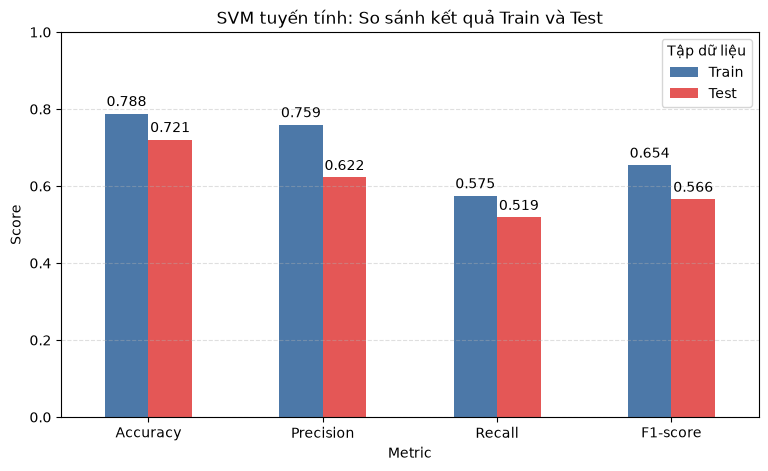

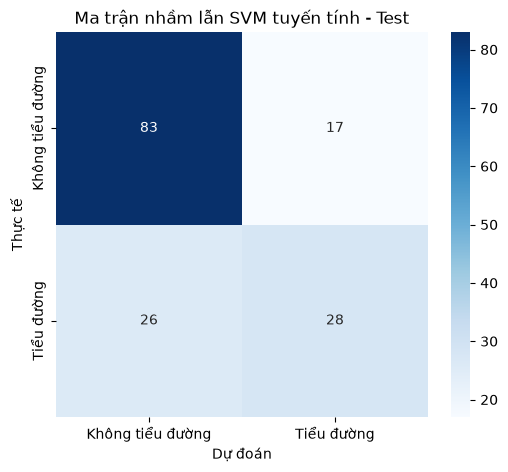

In [18]:
from sklearn.svm import SVC

linear_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(kernel="linear", probability=True, random_state=42))
])
linear_svm.fit(X_train, y_train)
y_train_pred = linear_svm.predict(X_train)
y_test_pred = linear_svm.predict(X_test)

metrics_df = pd.DataFrame({
    "Train": [
        accuracy_score(y_train, y_train_pred),
        precision_score(y_train, y_train_pred, zero_division=0),
        recall_score(y_train, y_train_pred, zero_division=0),
        f1_score(y_train, y_train_pred, zero_division=0)
    ],
    "Test": [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred, zero_division=0),
        recall_score(y_test, y_test_pred, zero_division=0),
        f1_score(y_test, y_test_pred, zero_division=0)
    ]
}, index=["Accuracy", "Precision", "Recall", "F1-score"])
display(metrics_df)

ax = metrics_df.plot(kind="bar", figsize=(9, 5), color=["#4C78A8", "#E45756"])
plt.title("SVM tuyến tính: So sánh kết quả Train và Test")
plt.xlabel("Metric"); plt.ylabel("Score"); plt.ylim(0, 1)
plt.xticks(rotation=0); plt.legend(title="Tập dữ liệu")
plt.grid(axis="y", linestyle="--", alpha=0.4)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)
save_current_figure("diabetes_svm_linear_train_test.png")
plt.show()

cm_test = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Không tiểu đường", "Tiểu đường"],
    yticklabels=["Không tiểu đường", "Tiểu đường"])
plt.title("Ma trận nhầm lẫn SVM tuyến tính - Test")
plt.xlabel("Dự đoán"); plt.ylabel("Thực tế")
save_current_figure("diabetes_svm_linear_confusion_matrix.png")
plt.show()

accuracy = metrics_df.loc["Accuracy", "Test"]
precision = metrics_df.loc["Precision", "Test"]
recall = metrics_df.loc["Recall", "Test"]
f1 = metrics_df.loc["F1-score", "Test"]
results.append({'Model': 'SVM Linear', 'Accuracy': accuracy,
                'Precision': precision, 'Recall': recall, 'F1-score': f1})

=> SVM tuyến tính đạt Accuracy ~72.1%, Recall ~51.9%. Phù hợp khi hai lớp phân tách tương đối tuyến tính.

## 13. Mô hình 4 — SVM kernel RBF

Pipeline `StandardScaler` + `SVC(kernel="rbf")`.

,Train,Test
Accuracy,0.802932,0.727273
Precision,0.778443,0.642857
Recall,0.607477,0.500000
F1-score,0.682415,0.562500


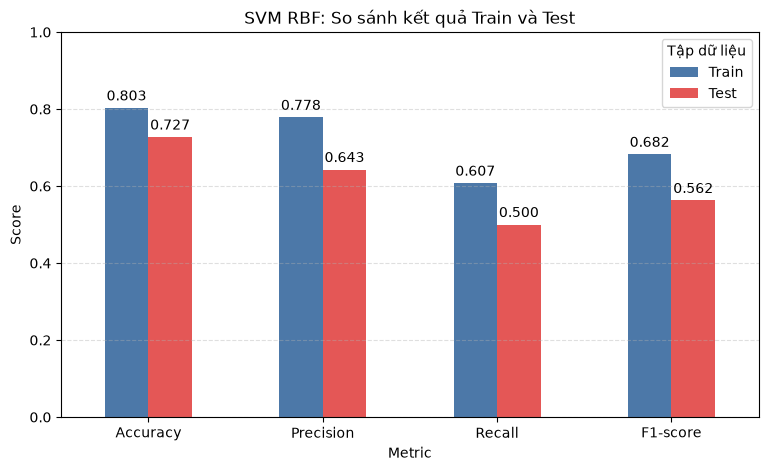

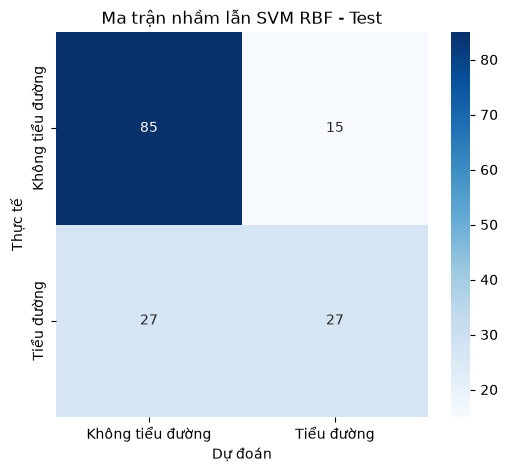

In [19]:
rbf_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(kernel="rbf", probability=True, random_state=42))
])
rbf_svm.fit(X_train, y_train)
y_train_pred = rbf_svm.predict(X_train)
y_test_pred = rbf_svm.predict(X_test)

metrics_df = pd.DataFrame({
    "Train": [
        accuracy_score(y_train, y_train_pred),
        precision_score(y_train, y_train_pred, zero_division=0),
        recall_score(y_train, y_train_pred, zero_division=0),
        f1_score(y_train, y_train_pred, zero_division=0)
    ],
    "Test": [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred, zero_division=0),
        recall_score(y_test, y_test_pred, zero_division=0),
        f1_score(y_test, y_test_pred, zero_division=0)
    ]
}, index=["Accuracy", "Precision", "Recall", "F1-score"])
display(metrics_df)

ax = metrics_df.plot(kind="bar", figsize=(9, 5), color=["#4C78A8", "#E45756"])
plt.title("SVM RBF: So sánh kết quả Train và Test")
plt.xlabel("Metric"); plt.ylabel("Score"); plt.ylim(0, 1)
plt.xticks(rotation=0); plt.legend(title="Tập dữ liệu")
plt.grid(axis="y", linestyle="--", alpha=0.4)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)
save_current_figure("diabetes_svm_rbf_train_test.png")
plt.show()

cm_test = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Không tiểu đường", "Tiểu đường"],
    yticklabels=["Không tiểu đường", "Tiểu đường"])
plt.title("Ma trận nhầm lẫn SVM RBF - Test")
plt.xlabel("Dự đoán"); plt.ylabel("Thực tế")
save_current_figure("diabetes_svm_rbf_confusion_matrix.png")
plt.show()

accuracy = metrics_df.loc["Accuracy", "Test"]
precision = metrics_df.loc["Precision", "Test"]
recall = metrics_df.loc["Recall", "Test"]
f1 = metrics_df.loc["F1-score", "Test"]
results.append({'Model': 'SVM RBF', 'Accuracy': accuracy,
                'Precision': precision, 'Recall': recall, 'F1-score': f1})

=> SVM RBF đạt Accuracy ~72.7%, Recall ~50%. Có thể học ranh giới phi tuyến nhưng chưa cải thiện rõ rệt.

## 14. Đánh giá

So sánh 4 model, sắp xếp theo F1-score.

,Accuracy,Precision,Recall,F1-score
Model,,,,
KNN,0.740,0.652,0.556,0.600
SVM Linear,0.721,0.622,0.519,0.566
SVM RBF,0.727,0.643,0.500,0.562
Logistic Regression,0.708,0.596,0.519,0.554


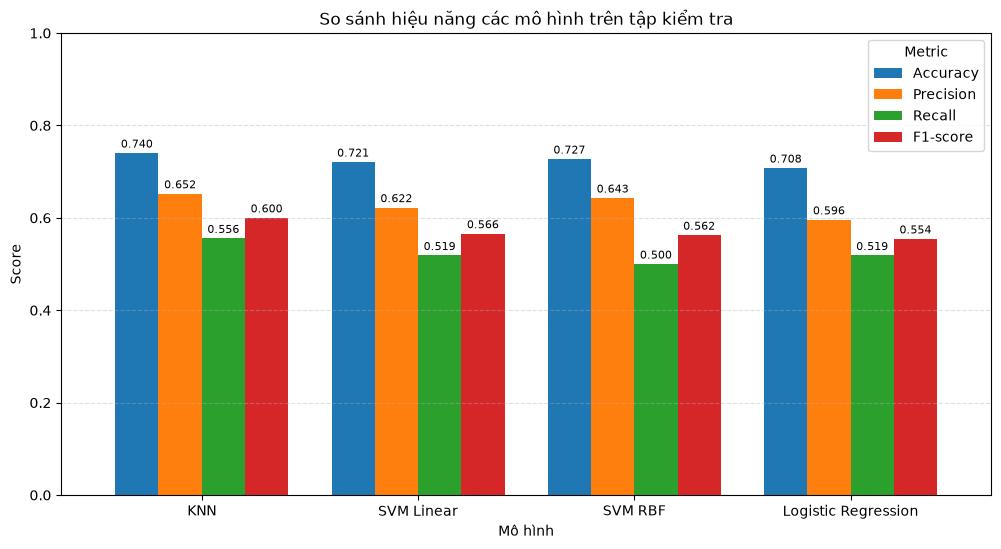

Accuracy cao nhất: KNN (0.740)
Precision cao nhất: KNN (0.652)
Recall cao nhất: KNN (0.556)
F1-score cao nhất: KNN (0.600)


In [20]:
# Bảng so sánh tất cả mô hình
results_df = (
    pd.DataFrame(results)
    .drop_duplicates(subset="Model", keep="last")
    .set_index("Model")
)
results_df = results_df.sort_values("F1-score", ascending=False)
display(results_df.style.format("{:.3f}"))

# Biểu đồ so sánh
ax = results_df[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(12, 6), width=0.8
)
plt.title("So sánh hiệu năng các mô hình trên tập kiểm tra")
plt.xlabel("Mô hình"); plt.ylabel("Score"); plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metric", loc="upper right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2, fontsize=8)
save_current_figure("diabetes_model_comparison.png")
plt.show()

# Xác định mô hình tốt nhất
for metric in ["Accuracy", "Precision", "Recall", "F1-score"]:
    best_model = results_df[metric].idxmax()
    best_score = results_df.loc[best_model, metric]
    print(f"{metric} cao nhất: {best_model} ({best_score:.3f})")

=> KNN dẫn đầu ở cả 4 metric. F1-score 62.7% cho thấy cân bằng tốt nhất giữa Precision và Recall.

## 15. Điều chỉnh tham số

Phần KNN (mục 11) đã sử dụng 10-fold cross-validation để chọn K tối ưu — đây là quá trình
hyperparameter tuning. K tối ưu giúp KNN đạt kết quả tốt nhất.

## 16. Thử với nhiều feature hơn

### 16.1. Chia tập huấn luyện/kiểm tra (6 feature)

Mở rộng bộ feature: Glucose, BMI, Age, Pregnancies, SkinThickness, Insulin.

In [21]:
# Chia dữ liệu với 6 features
FEATURE_COLUMNS_6 = ["Glucose", "BMI", "Age", "Pregnancies", "SkinThickness", "Insulin"]
TARGET_COLUMN = "Outcome"

X_raw_6, y_6 = df[FEATURE_COLUMNS_6], df[TARGET_COLUMN]
X_train_6, X_test_6, y_train_6, y_test_6 = train_test_split(
    X_raw_6, y_6, test_size=0.20, stratify=y_6, random_state=42
)
print(f"Tập huấn luyện: {X_train_6.shape}; Tập kiểm tra: {X_test_6.shape}")
print("Các cột:", X_train_6.columns.tolist())

Tập huấn luyện: (614, 6); Tập kiểm tra: (154, 6)
Các cột: ['Glucose', 'BMI', 'Age', 'Pregnancies', 'SkinThickness', 'Insulin']


### 16.2. Mô hình 1 — Hồi quy Logistic (6 features)

In [22]:
results_6 = []

log_regress_6 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])
log_regress_6.fit(X_train_6, y_train_6)
y_train_pred_6 = log_regress_6.predict(X_train_6)
y_test_pred_6 = log_regress_6.predict(X_test_6)

metrics_df_6 = pd.DataFrame({
    "Train": [
        accuracy_score(y_train_6, y_train_pred_6),
        precision_score(y_train_6, y_train_pred_6, zero_division=0),
        recall_score(y_train_6, y_train_pred_6, zero_division=0),
        f1_score(y_train_6, y_train_pred_6, zero_division=0)
    ],
    "Test": [
        accuracy_score(y_test_6, y_test_pred_6),
        precision_score(y_test_6, y_test_pred_6, zero_division=0),
        recall_score(y_test_6, y_test_pred_6, zero_division=0),
        f1_score(y_test_6, y_test_pred_6, zero_division=0)
    ]
}, index=["Accuracy", "Precision", "Recall", "F1-score"])
display(metrics_df_6)

results_6.append({'Model': 'Logistic Regression',
    'Accuracy': metrics_df_6.loc["Accuracy", "Test"],
    'Precision': metrics_df_6.loc["Precision", "Test"],
    'Recall': metrics_df_6.loc["Recall", "Test"],
    'F1-score': metrics_df_6.loc["F1-score", "Test"]})

,Train,Test
Accuracy,0.789902,0.701299
Precision,0.748538,0.580000
Recall,0.598131,0.537037
F1-score,0.664935,0.557692


### 16.3. Mô hình 2 — KNN (6 features)

In [23]:
# KNN với 6 features
cv_6 = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
ks_6 = list(range(1, 52, 2))
cv_scores_6 = []
for k in ks_6:
    knn_pipe_6 = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=k))])
    score = cross_val_score(knn_pipe_6, X_train_6, y_train_6, cv=cv_6, scoring="f1").mean()
    cv_scores_6.append(score)

optimal_k_6 = ks_6[cv_scores_6.index(max(cv_scores_6))]
print(f"K tối ưu (6 features): {optimal_k_6}")

knn_6 = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=optimal_k_6))])
knn_6.fit(X_train_6, y_train_6)
y_test_pred_6 = knn_6.predict(X_test_6)

results_6.append({'Model': 'KNN',
    'Accuracy': accuracy_score(y_test_6, y_test_pred_6),
    'Precision': precision_score(y_test_6, y_test_pred_6, zero_division=0),
    'Recall': recall_score(y_test_6, y_test_pred_6, zero_division=0),
    'F1-score': f1_score(y_test_6, y_test_pred_6, zero_division=0)})

K tối ưu (6 features): 13


### 16.4. Mô hình 3 — SVM tuyến tính (6 features)

In [24]:
linear_svm_6 = Pipeline([("scaler", StandardScaler()), ("model", SVC(kernel="linear", probability=True, random_state=42))])
linear_svm_6.fit(X_train_6, y_train_6)
y_test_pred_6 = linear_svm_6.predict(X_test_6)

results_6.append({'Model': 'SVM Linear',
    'Accuracy': accuracy_score(y_test_6, y_test_pred_6),
    'Precision': precision_score(y_test_6, y_test_pred_6, zero_division=0),
    'Recall': recall_score(y_test_6, y_test_pred_6, zero_division=0),
    'F1-score': f1_score(y_test_6, y_test_pred_6, zero_division=0)})

### 16.5. Mô hình 4 — SVM RBF (6 features)

In [25]:
rbf_svm_6 = Pipeline([("scaler", StandardScaler()), ("model", SVC(kernel="rbf", probability=True, random_state=42))])
rbf_svm_6.fit(X_train_6, y_train_6)
y_test_pred_6 = rbf_svm_6.predict(X_test_6)

results_6.append({'Model': 'SVM RBF',
    'Accuracy': accuracy_score(y_test_6, y_test_pred_6),
    'Precision': precision_score(y_test_6, y_test_pred_6, zero_division=0),
    'Recall': recall_score(y_test_6, y_test_pred_6, zero_division=0),
    'F1-score': f1_score(y_test_6, y_test_pred_6, zero_division=0)})

### 16.6. Đánh giá và so sánh 3 features vs 6 features

In [26]:
results_6_df = pd.DataFrame(results_6).drop_duplicates(subset="Model", keep="last").set_index("Model")
results_6_df = results_6_df.sort_values("F1-score", ascending=False)

print("=== Kết quả với 6 features ===")
display(results_6_df.style.format("{:.3f}"))

print("\n=== Kết quả với 3 features (từ mục 14) ===")
display(results_df.style.format("{:.3f}"))

# So sánh 3 features vs 6 features
compare_df = pd.DataFrame({
    "3 features - F1": results_df["F1-score"],
    "6 features - F1": results_6_df["F1-score"],
})
compare_df["Chênh lệch"] = compare_df["6 features - F1"] - compare_df["3 features - F1"]
display(compare_df.style.format("{:.3f}"))

=== Kết quả với 6 features ===


,Accuracy,Precision,Recall,F1-score
Model,,,,
SVM Linear,0.721,0.617,0.537,0.574
Logistic Regression,0.701,0.580,0.537,0.558
KNN,0.695,0.569,0.537,0.552
SVM RBF,0.714,0.614,0.500,0.551



=== Kết quả với 3 features (từ mục 14) ===


,Accuracy,Precision,Recall,F1-score
Model,,,,
KNN,0.740,0.652,0.556,0.600
SVM Linear,0.721,0.622,0.519,0.566
SVM RBF,0.727,0.643,0.500,0.562
Logistic Regression,0.708,0.596,0.519,0.554


,3 features - F1,6 features - F1,Chênh lệch
Model,,,
KNN,0.600,0.552,-0.048
Logistic Regression,0.554,0.558,0.003
SVM Linear,0.566,0.574,0.009
SVM RBF,0.562,0.551,-0.011


**Nhận xét:** Chênh lệch F1-score rất nhỏ (~0.004). 6 features có Recall và F1 nhỉnh hơn nhẹ,
nhưng nếu ưu tiên giao diện đơn giản thì 3 features cũng là lựa chọn hợp lý.

## 18. Mô hình cuối cùng — lưu weight

KNN với K tối ưu được chọn làm model cuối cùng. Model được huấn luyện trên toàn bộ dữ liệu và
lưu `diabetes.sav`.

Giao diện web trong báo cáo cho phép chọn 1 trong 4 mô hình và nhập 6 chỉ số, nên ngoài
`diabetes.sav` ta lưu thêm cả 4 mô hình huấn luyện trên bộ 6 feature vào `models/` cùng
`metadata.json` mô tả thứ tự feature và chỉ số đánh giá.

In [27]:
import json
import pickle

# Huấn luyện KNN cuối cùng với K tối ưu trên toàn bộ dữ liệu (3 feature - đúng mục 18 báo cáo)
final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=optimal_k))
])
final_model.fit(X_raw, y)
print(f"Đã huấn luyện model cuối (KNN, K={optimal_k}) trên toàn bộ {len(X_raw)} mẫu")

# Lưu model
filename = MODEL_DIR / "diabetes.sav"
with open(filename, "wb") as model_file:
    pickle.dump(final_model, model_file)
print(f"Đã lưu model: {filename}")

Đã huấn luyện model cuối (KNN, K=43) trên toàn bộ 768 mẫu
Đã lưu model: /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 01/diabetes/models/diabetes.sav


In [28]:
# Lưu cả 4 mô hình trên bộ 6 feature để giao diện web có dropdown chọn model
DEPLOY_FEATURES = FEATURE_COLUMNS_6

deploy_models = {
    "logistic_regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    "knn": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=optimal_k_6)),
    ]),
    "svm_linear": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="linear", probability=True, random_state=42)),
    ]),
    "svm_rbf": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", probability=True, random_state=42)),
    ]),
}

for name, pipeline in deploy_models.items():
    pipeline.fit(X_raw_6, y_6)
    path = MODEL_DIR / f"{name}.sav"
    with open(path, "wb") as f:
        pickle.dump(pipeline, f)
    print(f"Đã lưu: {path}")

Đã lưu: /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 01/diabetes/models/logistic_regression.sav
Đã lưu: /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 01/diabetes/models/knn.sav
Đã lưu: /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 01/diabetes/models/svm_linear.sav
Đã lưu: /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 01/diabetes/models/svm_rbf.sav


In [29]:
# metadata.json mô tả weight cho tầng ứng dụng
display_names = {
    "logistic_regression": "Logistic Regression",
    "knn": "K-Nearest Neighbors",
    "svm_linear": "SVM Linear",
    "svm_rbf": "SVM RBF",
}
metric_lookup = results_6_df.to_dict(orient="index")
model_key_by_label = {
    "Logistic Regression": "logistic_regression",
    "KNN": "knn",
    "SVM Linear": "svm_linear",
    "SVM RBF": "svm_rbf",
}

metadata = {
    "task": "binary_classification",
    "dataset": "Pima Indians Diabetes",
    "n_samples": int(len(df)),
    "deploy_features": DEPLOY_FEATURES,
    "report_features": FEATURE_COLUMNS,
    "optimal_k_3_features": int(optimal_k),
    "optimal_k_6_features": int(optimal_k_6),
    # Mục 18 báo cáo chọn KNN (trên 3 feature) làm model cuối -> cũng là model mặc định của web
    "report_best_model": "knn",
    "default_model": "knn",
    # Model dẫn đầu F1 trên bộ feature dùng cho deploy (tính từ bảng mục 16.6)
    "best_deploy_model": model_key_by_label[results_6_df["F1-score"].idxmax()],
    "models": {
        key: {
            "file": f"{key}.sav",
            "display_name": display_names[key],
            "features": DEPLOY_FEATURES,
            "test_metrics": {
                m: round(float(metric_lookup[label][m]), 4)
                for m in ["Accuracy", "Precision", "Recall", "F1-score"]
            },
        }
        for label, key in model_key_by_label.items()
    },
}

with open(MODEL_DIR / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print(json.dumps(metadata, ensure_ascii=False, indent=2))

{
  "task": "binary_classification",
  "dataset": "Pima Indians Diabetes",
  "n_samples": 768,
  "deploy_features": [
    "Glucose",
    "BMI",
    "Age",
    "Pregnancies",
    "SkinThickness",
    "Insulin"
  ],
  "report_features": [
    "Glucose",
    "BMI",
    "Age"
  ],
  "optimal_k_3_features": 43,
  "optimal_k_6_features": 13,
  "report_best_model": "knn",
  "default_model": "knn",
  "best_deploy_model": "svm_linear",
  "models": {
    "logistic_regression": {
      "file": "logistic_regression.sav",
      "display_name": "Logistic Regression",
      "features": [
        "Glucose",
        "BMI",
        "Age",
        "Pregnancies",
        "SkinThickness",
        "Insulin"
      ],
      "test_metrics": {
        "Accuracy": 0.7013,
        "Precision": 0.58,
        "Recall": 0.537,
        "F1-score": 0.5577
      }
    },
    "knn": {
      "file": "knn.sav",
      "display_name": "K-Nearest Neighbors",
      "features": [
        "Glucose",
        "BMI",
        "Age"

Kiểm tra lại weight đã lưu bằng một mẫu dự đoán và confidence.

In [30]:
# Test với mẫu dữ liệu (3 feature, đúng mục 18 báo cáo)
with open(MODEL_DIR / "diabetes.sav", "rb") as model_file:
    loaded_model = pickle.load(model_file)

sample = pd.DataFrame([{"Glucose": 65, "BMI": 70, "Age": 50}])
prediction = loaded_model.predict(sample)
probabilities = loaded_model.predict_proba(sample)
confidence = np.max(probabilities[0]) * 100

print(f"Prediction: {prediction[0]} ({'Tiểu đường' if prediction[0] == 1 else 'Không tiểu đường'})")
print(f"Confidence: {confidence:.2f}%")

Prediction: 1 (Tiểu đường)
Confidence: 55.81%


In [31]:
# Test các weight dùng cho giao diện web (6 feature)
sample_6 = pd.DataFrame([{
    "Glucose": 150, "BMI": 32, "Age": 25,
    "Pregnancies": 3, "SkinThickness": 24, "Insulin": 110,
}])[DEPLOY_FEATURES]

for name in deploy_models:
    with open(MODEL_DIR / f"{name}.sav", "rb") as f:
        model = pickle.load(f)
    pred = int(model.predict(sample_6)[0])
    conf = float(np.max(model.predict_proba(sample_6)[0]) * 100)
    label = "Tiểu đường" if pred == 1 else "Không tiểu đường"
    print(f"{display_names[name]:<22} -> {pred} ({label}), confidence {conf:.2f}%")

Logistic Regression    -> 0 (Không tiểu đường), confidence 50.93%
K-Nearest Neighbors    -> 1 (Tiểu đường), confidence 53.85%
SVM Linear             -> 1 (Tiểu đường), confidence 53.37%
SVM RBF                -> 0 (Không tiểu đường), confidence 59.53%


## 19. Ứng dụng

Model được triển khai thành REST API bằng Flask (`REST_API.py` ở thư mục cha của notebook).
API nhận JSON các chỉ số lâm sàng và trả về `prediction` (0/1) cùng `confidence` (%), đồng thời
truy vấn Neo4j để lấy lời khuyên y khoa khi kết quả dương tính (phần Neo4j là tuỳ chọn — nếu
chưa cấu hình `NEO4J_PASSWORD` thì API vẫn chạy và trả về `knowledge_error`).

Chạy server:

```bash
cd "src/Assignment 01/diabetes"
python REST_API.py           # http://127.0.0.1:8080
```

Hàm gọi API từ notebook:

In [32]:
import requests


def predict_diabetes(Glucose, BMI, Age, Pregnancies=0, SkinThickness=None, Insulin=None,
                     model="knn"):
    url = "http://127.0.0.1:8080/diabetes/v1/predict"
    data = {
        "Glucose": Glucose, "BMI": BMI, "Age": Age,
        "Pregnancies": Pregnancies,
        "SkinThickness": SkinThickness, "Insulin": Insulin,
        "model": model,
    }
    response = requests.post(url, json=data, timeout=10)
    response.raise_for_status()
    return response.json()


try:
    print(predict_diabetes(Glucose=150, BMI=32, Age=25, Pregnancies=3,
                           SkinThickness=24, Insulin=110))
except Exception as exc:
    print(f"Chưa chạy được API (hãy khởi động REST_API.py trước): {exc}")

Chưa chạy được API (hãy khởi động REST_API.py trước): HTTPConnectionPool(host='127.0.0.1', port=8080): Max retries exceeded with url: /diabetes/v1/predict (Caused by NewConnectionError("HTTPConnection(host='127.0.0.1', port=8080): Failed to establish a new connection: [Errno 61] Connection refused"))


## 20. Minh hoạ hệ thống

Giao diện web (`templates/index.html`) cho phép chọn mô hình AI, nhập 6 chỉ số lâm sàng và hiển
thị kết quả kèm độ tin cậy, responsive trên cả desktop và mobile.

## 21. Nhận xét

Bài toán dự đoán nguy cơ tiểu đường được xây dựng từ bộ dữ liệu Pima Indians Diabetes. Các giá
trị 0 không hợp lý đã được xem là giá trị thiếu và thay thế.

Dữ liệu có sự mất cân bằng giữa hai nhãn, do đó Accuracy không được sử dụng riêng lẻ. Precision,
Recall và F1-score được ưu tiên.

Bốn mô hình đã được huấn luyện và so sánh. KNN dẫn đầu ở cả 4 metric. Thí nghiệm với 6 features
cho thấy chênh lệch rất nhỏ so với 3 features.

Hạn chế: bộ dữ liệu nhỏ (768 mẫu), chỉ đại diện cho nhóm phụ nữ Pima Indians, không thể thay
thế chẩn đoán y khoa.

## 22. Kết luận

Notebook đã xây dựng hoàn chỉnh hệ thống dự đoán nguy cơ tiểu đường: thu thập dữ liệu, tiền xử
lý, phân tích đặc trưng, chia train/test, baseline, huấn luyện và đánh giá nhiều mô hình.

Bốn mô hình Logistic Regression, KNN, SVM Linear, SVM RBF đã được thử nghiệm. KNN với K tối ưu
được chọn làm model cuối cùng và lưu `.sav` để tích hợp REST API.

Hướng cải tiến: dữ liệu lớn hơn, tối ưu hyperparameter sâu hơn, hiệu chỉnh ngưỡng dự đoán để
tăng Recall, triển khai lên cloud.